# 1. Model Comparison

This notebook brings together the results of the classical machine-learning, neural-network, and transformer experiments to assess their relative predictive performance and computational requirements.

The analysis uses the saved validation results generated in the preceding notebooks. Models are not retrained, and the official test set is not accessed. The purpose is to compare the experiments conducted during model development and identify promising configurations for further investigation.

Sixteen experiment configurations are included: twelve classical machine-learning configurations, two neural-network models, and two transformer-based approaches. Their performance is examined using accuracy, macro precision, macro recall, macro F1, and weighted F1. The analysis also considers per-class performance, confusion patterns, training time, inference time, throughput, artifact size, and available memory measurements.

Macro F1 is the primary metric for comparing predictive performance. It calculates the F1 score independently for each class and then gives each class equal weight when calculating the overall result. This is particularly useful for a multi-class problem because strong performance on some categories cannot completely conceal weaker performance on others.

An important consideration is that the experiments do not all use the same text representation. The classical models were evaluated using both complete messages and extracted message bodies, whereas the neural-network and transformer experiments used message bodies. The overall ranking is therefore useful for identifying the strongest evaluated configuration, but it does not provide a perfectly controlled comparison of model architectures.

For this reason, the notebook also includes comparisons restricted to the `message_body` representation. These provide a more consistent basis for comparing the different model families, while recognising that their tokenisation, feature construction, and training procedures still differ.

In [1]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda value: f"{value:.4f}")

PROJECT_ROOT = Path.cwd()

if not (PROJECT_ROOT / "results/logs/model_comparison.json").is_file():
    PROJECT_ROOT = PROJECT_ROOT.parent

COMPARISON_PATH = PROJECT_ROOT / "results/logs/model_comparison.json"
METRICS_PATH = PROJECT_ROOT / "results/metrics/model_comparison.csv"

assert COMPARISON_PATH.is_file(), (
    f"Comparison results not found: {COMPARISON_PATH}. "
    "Run scripts/evaluate_models.py from the project root first."
)

assert METRICS_PATH.is_file(), (
    f"Comparison metrics not found: {METRICS_PATH}. "
    "Run scripts/evaluate_models.py from the project root first."
)

print(f"Project root: {PROJECT_ROOT}")
print(f"Detailed results: {COMPARISON_PATH}")
print(f"Metrics table: {METRICS_PATH}")

Project root: /home/nkululekocyrilcele/projects/topicsense-nlp
Detailed results: /home/nkululekocyrilcele/projects/topicsense-nlp/results/logs/model_comparison.json
Metrics table: /home/nkululekocyrilcele/projects/topicsense-nlp/results/metrics/model_comparison.csv


## 1.1 Loading and Validating the Comparison Results

The consolidated comparison results are loaded from the JSON and CSV files generated by the model-comparison script.

The JSON file contains the detailed experiment records, including the model configurations, validation metrics, and additional evaluation information. The CSV file provides a tabular representation that can be used to rank configurations, compare model families, and create visualisations.

Before the analysis proceeds, the notebook checks that all sixteen expected experiment runs are present. It also verifies that the records confirm that the official test set was not used.

These checks are important because the comparison must use the results generated by the completed experiments rather than incomplete, inconsistent, or accidentally mixed evaluation records.

In [2]:
with COMPARISON_PATH.open("r", encoding="utf-8") as file:
    comparison = json.load(file)

comparison_df = pd.read_csv(METRICS_PATH)

metadata = comparison["metadata"]
runs = comparison["runs"]

assert len(runs) == 16, (
    f"Expected 16 experiment runs, found {len(runs)}."
)

assert metadata["experiment_count"] == 16

assert metadata["test_data_used"] is False, (
    "The consolidated comparison indicates that test data was used."
)

assert len(comparison_df) == 16

print("Comparison validation passed.")
print(f"Experiment runs: {len(runs)}")
print(f"Dataset: {metadata['dataset']}")
print(f"Training documents: {metadata['training_documents']:,}")
print(f"Validation documents: {metadata['validation_documents']:,}")
print(f"Random seed: {metadata['random_seed']}")
print(f"Official test data used: {metadata['test_data_used']}")

Comparison validation passed.
Experiment runs: 16
Dataset: 20newsgroups
Training documents: 9,051
Validation documents: 2,263
Random seed: 42
Official test data used: False


### Interpreting the Comparison Metadata

The validation confirms that the comparison contains sixteen experiment runs: twelve classical machine-learning configurations, two neural-network models, and two transformer-based approaches.

All experiments use the same development training and validation partitions, comprising 9,051 training documents and 2,263 validation documents. The recorded random seed is 42.

Most importantly, the comparison records confirm that the official test set was not used. This preserves the separation between model development and final evaluation. The validation results can therefore be used to compare configurations and inform model selection, but they must not be presented as final evidence of performance on unseen test data.

## 1.2 Overall Model Ranking

The following ranking orders all sixteen experiment configurations by validation macro F1, from highest to lowest.

Accuracy, macro precision, macro recall, and weighted F1 are included to provide additional context. Although macro F1 is the primary ranking metric, the other measures help show whether a configuration's performance is consistent across different evaluation perspectives.

The ranking is based on individual configurations rather than model families. This distinction matters because the classical experiments vary across classifier type, feature extraction method, and text representation.

In [3]:
ranking_columns = [
    column
    for column in [
        "run_id",
        "model_family",
        "model",
        "classifier",
        "feature_type",
        "representation",
        "accuracy",
        "macro_precision",
        "macro_recall",
        "macro_f1",
        "weighted_f1",
    ]
    if column in comparison_df.columns
]

overall_ranking = (
    comparison_df
    .sort_values("macro_f1", ascending=False)
    .reset_index(drop=True)
)

overall_ranking.index = overall_ranking.index + 1
overall_ranking.index.name = "rank"

display(overall_ranking[ranking_columns])

,run_id,model_family,model,feature_type,representation,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1
rank,,,,,,,,,,
1,linear_svm__tfidf__full_message,Classical ML,Linear SVM,tfidf,full_message,0.9147,0.9170,0.9125,0.9138,0.9147
2,linear_svm__tfidf__message_body,Classical ML,Linear SVM,tfidf,message_body,0.8966,0.8999,0.8929,0.8947,0.8963
3,logistic_regression__tfidf__full_message,Classical ML,Logistic Regression,tfidf,full_message,0.8811,0.8882,0.8769,0.8795,0.8812
4,linear_svm__count__full_message,Classical ML,Linear SVM,count,full_message,0.8780,0.8823,0.8770,0.8789,0.8785
5,logistic_regression__count__full_message,Classical ML,Logistic Regression,count,full_message,0.8732,0.8774,0.8710,0.8731,0.8735
6,logistic_regression__tfidf__message_body,Classical ML,Logistic Regression,tfidf,message_body,0.8604,0.8721,0.8528,0.8550,0.8592
7,multinomial_nb__tfidf__full_message,Classical ML,Multinomial Naive Bayes,tfidf,full_message,0.8409,0.8657,0.8285,0.8293,0.8375
8,multinomial_nb__count__full_message,Classical ML,Multinomial Naive Bayes,count,full_message,0.8383,0.8558,0.8376,0.8272,0.8261
9,logistic_regression__count__message_body,Classical ML,Logistic Regression,count,message_body,0.8219,0.8294,0.8188,0.8219,0.8229


### Interpreting the Overall Ranking

The ranking identifies the Linear SVM using TF-IDF features and the complete-message representation as the strongest configuration. It achieves a validation macro F1 of 0.9138, with an accuracy of 0.9147 and a weighted F1 of 0.9147.

The second-ranked configuration uses the same classifier and feature extraction method but operates on extracted message bodies. Its macro F1 is 0.8947. The difference between these two results is 0.0191, indicating that the choice of text representation is associated with a measurable difference in validation performance for this configuration.

The strongest neural-network and transformer results appear lower in the ranking. TextCNN achieves a macro F1 of 0.7774, while the frozen SentenceTransformer approach achieves 0.7755. DistilBERT achieves 0.7709, and the BiLSTM achieves 0.5465.

These results establish that the strongest observed configuration belongs to the classical machine-learning family. However, the overall ranking combines complete-message and message-body experiments. It therefore identifies the best-performing configuration in the current experiment set, rather than isolating the effect of model architecture.

The subsequent comparisons address this limitation by examining the classical configurations individually and then restricting the comparison to message bodies.

## 1.3 Comparing Classical Machine-Learning Configurations

The classical experiments investigate three classifiers:

- Multinomial Naive Bayes
- Logistic Regression
- Linear Support Vector Machine

Each classifier was evaluated using CountVectorizer and TF-IDF features, with both complete messages and extracted message bodies.

This produces twelve configurations. Comparing them helps establish how feature extraction and text representation influence classification performance within the classical machine-learning family.

In [20]:
classical_df = comparison_df[
    comparison_df["model_family"] == "Classical ML"
].copy()

assert len(classical_df) == 12, (
    f"Expected 12 classical configurations, found {len(classical_df)}."
)

classical_df["configuration"] = (
    classical_df["model"].astype(str)
    + " | "
    + classical_df["feature_type"].astype(str)
    + " | "
    + classical_df["representation"].astype(str)
)

classical_ranking = (
    classical_df
    .sort_values("macro_f1", ascending=False)
    .reset_index(drop=True)
)

display(
    classical_ranking[
        [
            "model",
            "feature_type",
            "representation",
            "accuracy",
            "macro_f1",
            "weighted_f1",
        ]
    ]
)

,model,feature_type,representation,accuracy,macro_f1,weighted_f1
0,Linear SVM,tfidf,full_message,0.9147,0.9138,0.9147
1,Linear SVM,tfidf,message_body,0.8966,0.8947,0.8963
2,Logistic Regression,tfidf,full_message,0.8811,0.8795,0.8812
3,Linear SVM,count,full_message,0.8780,0.8789,0.8785
4,Logistic Regression,count,full_message,0.8732,0.8731,0.8735
5,Logistic Regression,tfidf,message_body,0.8604,0.8550,0.8592
6,Multinomial Naive Bayes,tfidf,full_message,0.8409,0.8293,0.8375
7,Multinomial Naive Bayes,count,full_message,0.8383,0.8272,0.8261
8,Logistic Regression,count,message_body,0.8219,0.8219,0.8229
9,Multinomial Naive Bayes,tfidf,message_body,0.8184,0.8053,0.8154


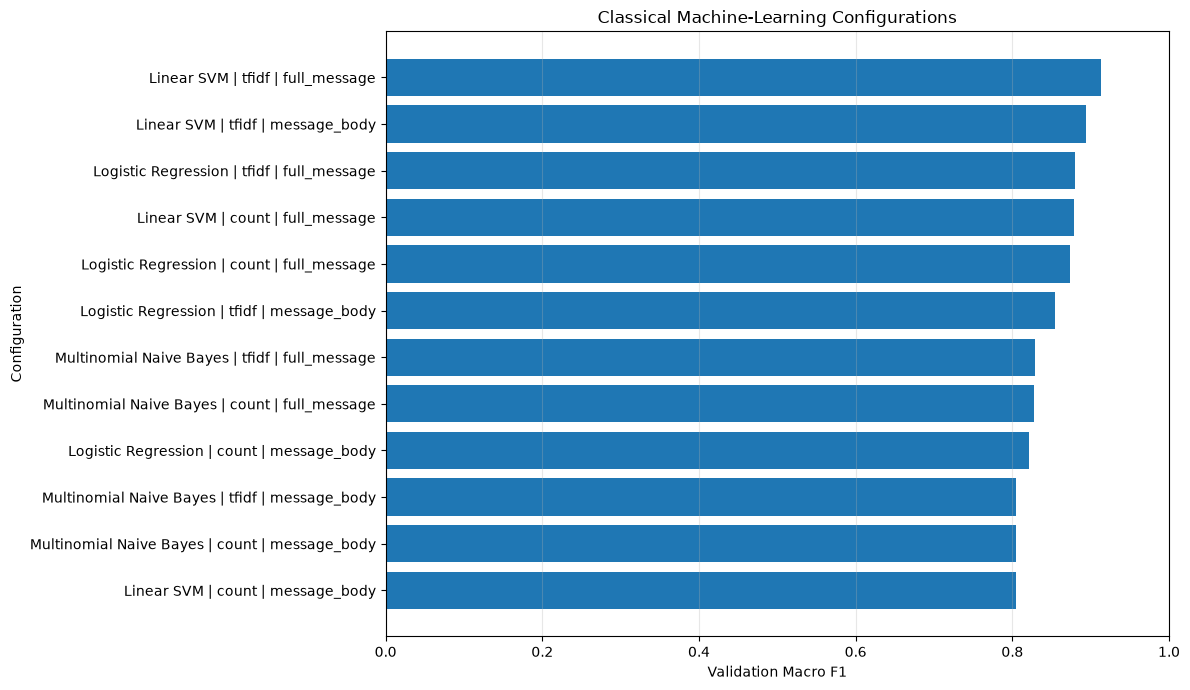

In [21]:
classical_plot = classical_ranking.sort_values("macro_f1")

fig, ax = plt.subplots(figsize=(12, 7))

ax.barh(
    classical_plot["configuration"],
    classical_plot["macro_f1"],
)

ax.set_title("Classical Machine-Learning Configurations")
ax.set_xlabel("Validation Macro F1")
ax.set_ylabel("Configuration")
ax.set_xlim(0, 1)

ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

### Interpreting the Classical Model Results

The twelve classical configurations show that classification performance depends on the combination of classifier, feature extraction method, and text representation.

The strongest result is obtained by the Linear SVM with TF-IDF features and complete messages, achieving a macro F1 of 0.9138. Its message-body counterpart achieves 0.8947. Logistic Regression also performs better with TF-IDF than with count-based features in the configurations evaluated, while Multinomial Naive Bayes records lower macro F1 scores than the other two classifiers.

The results also show a consistent advantage for the complete-message representation over the corresponding message-body configurations within these experiments. For example, the Linear SVM with count features achieves 0.8789 macro F1 using complete messages, compared with 0.8046 using message bodies.

This difference warrants careful interpretation. Complete messages retain information outside the extracted message body, including headers and quoted discussion material. Such information may contain useful signals for distinguishing newsgroups, but it may also introduce dataset-specific patterns that do not generalise as reliably to other sources of text.

The results therefore suggest that the additional information in complete messages is useful for this benchmark. They do not establish which specific parts of that information account for the improvement. Further controlled experiments would be required to isolate the contributions of headers, quoted text, and other message structure.

## 1.4 Best Classical Configuration by Classifier

The next comparison identifies the strongest configuration for each classical classifier.

This provides a more focused assessment of the three algorithms by allowing each one to be represented by its best-performing combination of feature extraction and text representation.

The results are selected using validation macro F1.

In [22]:
best_classical_by_classifier = (
    classical_df
    .sort_values("macro_f1", ascending=False)
    .groupby("model", as_index=False)
    .first()
    .sort_values("macro_f1", ascending=False)
    .reset_index(drop=True)
)

display(
    best_classical_by_classifier[
        [
            "model",
            "feature_type",
            "representation",
            "accuracy",
            "macro_f1",
            "weighted_f1",
        ]
    ]
)

,model,feature_type,representation,accuracy,macro_f1,weighted_f1
0,Linear SVM,tfidf,full_message,0.9147,0.9138,0.9147
1,Logistic Regression,tfidf,full_message,0.8811,0.8795,0.8812
2,Multinomial Naive Bayes,tfidf,full_message,0.8409,0.8293,0.8375


### Interpreting the Classifier Comparison

When each classical classifier is represented by its strongest validation configuration, the Linear SVM achieves the highest macro F1 at 0.9138. Logistic Regression follows with 0.8795, while Multinomial Naive Bayes achieves 0.8293.

All three classifiers achieve their best results in this comparison using TF-IDF features and the complete-message representation.

This provides a useful basis for selecting a classical model for further investigation. The Linear SVM is the strongest candidate among the three algorithms under the configurations evaluated.

However, these are validation-based results. Selecting the best configuration using validation performance does not guarantee that the same ordering will be observed on the official test set.

## 1.5 Controlled Comparison Using Message Bodies

The overall ranking combines experiments using complete messages and extracted message bodies. This introduces a difference in input representation that complicates direct comparisons between model families.

To reduce this source of variation, the following analysis restricts the comparison to experiments using `message_body`.

The table selects the strongest validation configuration within each model family. It therefore compares the best classical machine-learning result, the best neural-network result, and the best transformer result within this representation.

Holding the broad text representation constant makes the comparison more informative, but it does not completely isolate the effect of architecture. The approaches still differ in tokenisation, feature construction, model capacity, and training procedures.

In [23]:
message_body_df = comparison_df[
    comparison_df["representation"] == "message_body"
].copy()

assert not message_body_df.empty

best_message_body_by_family = (
    message_body_df
    .sort_values("macro_f1", ascending=False)
    .groupby("model_family", as_index=False)
    .first()
    .sort_values("macro_f1", ascending=False)
    .reset_index(drop=True)
)

display(
    best_message_body_by_family[
        [
            "model_family",
            "model",
            "feature_type",
            "accuracy",
            "macro_f1",
            "weighted_f1",
        ]
    ]
)

,model_family,model,feature_type,accuracy,macro_f1,weighted_f1
0,Classical ML,Linear SVM,tfidf,0.8966,0.8947,0.8963
1,Neural network,TextCNN,NaN,0.7795,0.7774,0.7793
2,Transformer,Frozen SentenceTransformer,NaN,0.7857,0.7755,0.7843


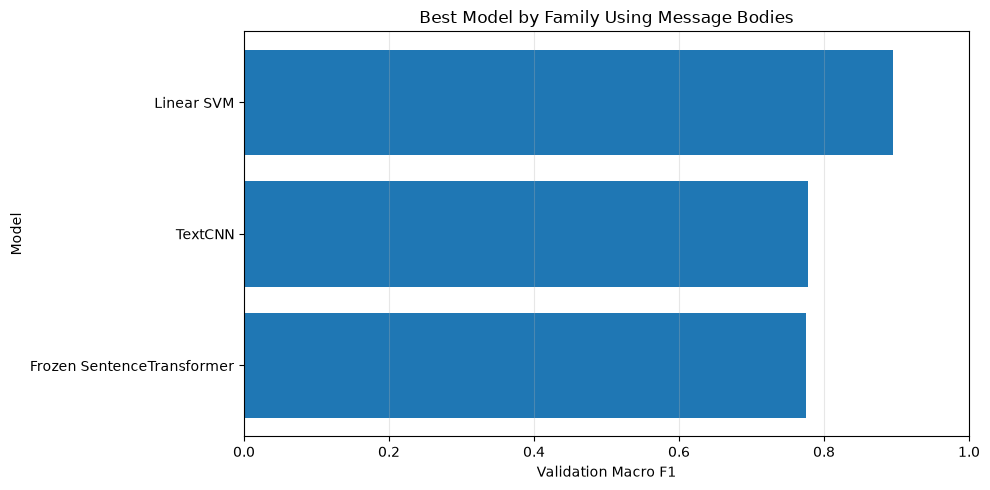

In [8]:
matched_plot = best_message_body_by_family.sort_values("macro_f1")

fig, ax = plt.subplots(figsize=(10, 5))

ax.barh(
    matched_plot["model"],
    matched_plot["macro_f1"],
)

ax.set_title("Best Model by Family Using Message Bodies")
ax.set_xlabel("Validation Macro F1")
ax.set_ylabel("Model")
ax.set_xlim(0, 1)

ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

### Interpreting the Message-Body Comparison

The message-body comparison continues to favour classical machine learning. The strongest classical configuration is the Linear SVM with TF-IDF features, achieving a macro F1 of 0.8947.

The strongest neural-network configuration is TextCNN, with a macro F1 of 0.7774. The strongest transformer configuration is the frozen SentenceTransformer approach, achieving 0.7755.

The other message-body results provide additional context. DistilBERT achieves a macro F1 of 0.7709, while the BiLSTM achieves 0.5465. The relatively small differences between TextCNN, the frozen embedding approach, and DistilBERT should not be treated as evidence of a meaningful performance difference without repeated experiments or appropriate statistical analysis.

The difference between the strongest classical result and the neural-network and transformer results is considerably larger than the differences among those three approaches. This indicates that the classical model remains highly competitive even when the broad text representation is held constant.

Nevertheless, this comparison is not a perfectly controlled architecture experiment. The models use different tokenisation and feature-generation procedures, and their training strategies differ. The results should therefore be interpreted as a comparison of the implemented approaches rather than a definitive ranking of the underlying model architectures.

Overall, the findings demonstrate that greater model complexity does not automatically translate into better validation performance. The suitability of an approach depends on the dataset, input representation, model configuration, and available computational resources.

## 1.6 Performance Across Model Families

The following visualisation provides an overview of the strongest validation result obtained by each model family.

For classical machine learning, the best configuration is selected from all twelve experiments. For neural networks and transformers, the strongest result within each family is selected.

This comparison is useful for identifying the strongest available approach in each family, although the representation differences discussed earlier must remain part of the interpretation.

,model_family,model,feature_type,representation,accuracy,macro_f1,weighted_f1
0,Classical ML,Linear SVM,tfidf,full_message,0.9147,0.9138,0.9147
1,Neural network,TextCNN,NaN,message_body,0.7795,0.7774,0.7793
2,Transformer,Frozen SentenceTransformer,NaN,message_body,0.7857,0.7755,0.7843


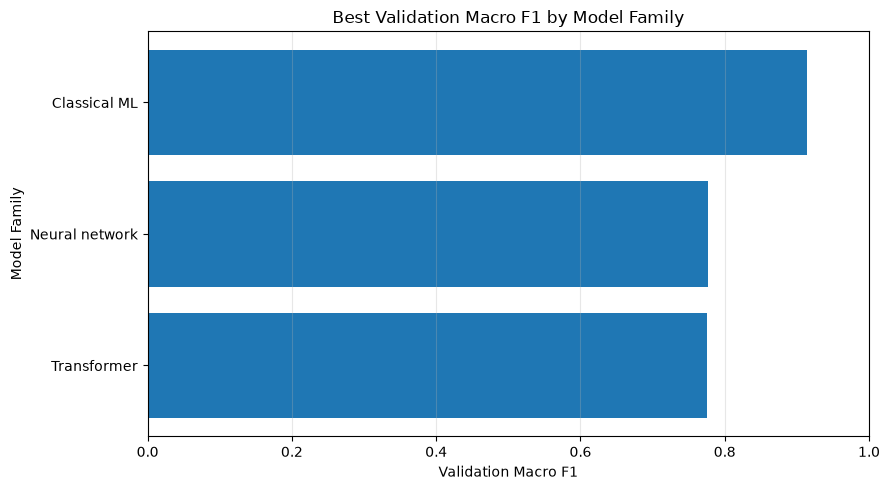

In [24]:
best_by_family = (
    comparison_df
    .sort_values("macro_f1", ascending=False)
    .groupby("model_family", as_index=False)
    .first()
    .sort_values("macro_f1", ascending=False)
    .reset_index(drop=True)
)

display(
    best_by_family[
        [
            "model_family",
            "model",
            "feature_type",
            "representation",
            "accuracy",
            "macro_f1",
            "weighted_f1",
        ]
    ]
)

fig, ax = plt.subplots(figsize=(9, 5))

family_plot = best_by_family.sort_values("macro_f1")

ax.barh(
    family_plot["model_family"],
    family_plot["macro_f1"],
)

ax.set_title("Best Validation Macro F1 by Model Family")
ax.set_xlabel("Validation Macro F1")
ax.set_ylabel("Model Family")
ax.set_xlim(0, 1)

ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

### Interpreting Model-Family Performance

The family-level comparison identifies classical machine learning as the strongest approach in the current experiments. Its best configuration achieves a validation macro F1 of 0.9138, compared with 0.7774 for the best neural-network configuration and 0.7755 for the best transformer configuration.

The comparison provides a useful summary of the strongest available result in each family. However, the classical result uses complete messages, whereas the neural-network and transformer results use message bodies. The family-level ranking should therefore not be interpreted as a fully controlled comparison.

The message-body analysis in the preceding section provides a more consistent comparison of the input representation. It also shows that the best classical configuration retains a substantial performance advantage under that restriction.

These findings are specific to the dataset and experimental configurations used in this project. They do not establish that classical machine learning will outperform neural networks or transformers on other text-classification tasks.

The results do, however, provide a strong validation baseline against which the additional computational requirements of more complex approaches can be assessed.

## 1.7 Per-Class Performance

Aggregate metrics provide a useful summary, but they can conceal differences in performance across individual categories.

The following analysis examines the per-class precision, recall, and F1 scores of the strongest overall validation configuration.

This allows us to identify categories that are classified reliably and categories that remain more difficult for the selected model.

In [25]:
best_run = max(
    runs,
    key=lambda run: run["macro_f1"],
)

best_run_id = best_run["run_id"]

print(f"Best configuration: {best_run['model']}")
print(f"Run ID: {best_run_id}")
print(f"Representation: {best_run['representation']}")
print(f"Validation macro F1: {best_run['macro_f1']:.4f}")

assert "per_class_metrics" in best_run, (
    "Per-class metrics are missing from the best experiment record."
)

per_class_df = (
    pd.DataFrame.from_dict(
        best_run["per_class_metrics"],
        orient="index",
    )
    .rename_axis("class")
    .reset_index()
)

per_class_df = per_class_df.sort_values(
    "f1_score",
    ascending=False,
).reset_index(drop=True)

display(per_class_df)

Best configuration: Linear SVM
Run ID: linear_svm__tfidf__full_message
Representation: full_message
Validation macro F1: 0.9138


,class,precision,recall,f1_score,support
0,talk.politics.mideast,0.9658,1.0000,0.9826,113
1,sci.space,0.9829,0.9746,0.9787,118
2,sci.crypt,0.9748,0.9748,0.9748,119
3,rec.motorcycles,0.9661,0.9500,0.9580,120
4,talk.politics.guns,0.9304,0.9817,0.9554,109
5,rec.sport.hockey,0.9739,0.9333,0.9532,120
6,rec.sport.baseball,0.9350,0.9664,0.9504,119
7,soc.religion.christian,0.9206,0.9667,0.9431,120
8,alt.atheism,0.9570,0.9271,0.9418,96
9,talk.politics.misc,0.9362,0.9462,0.9412,93


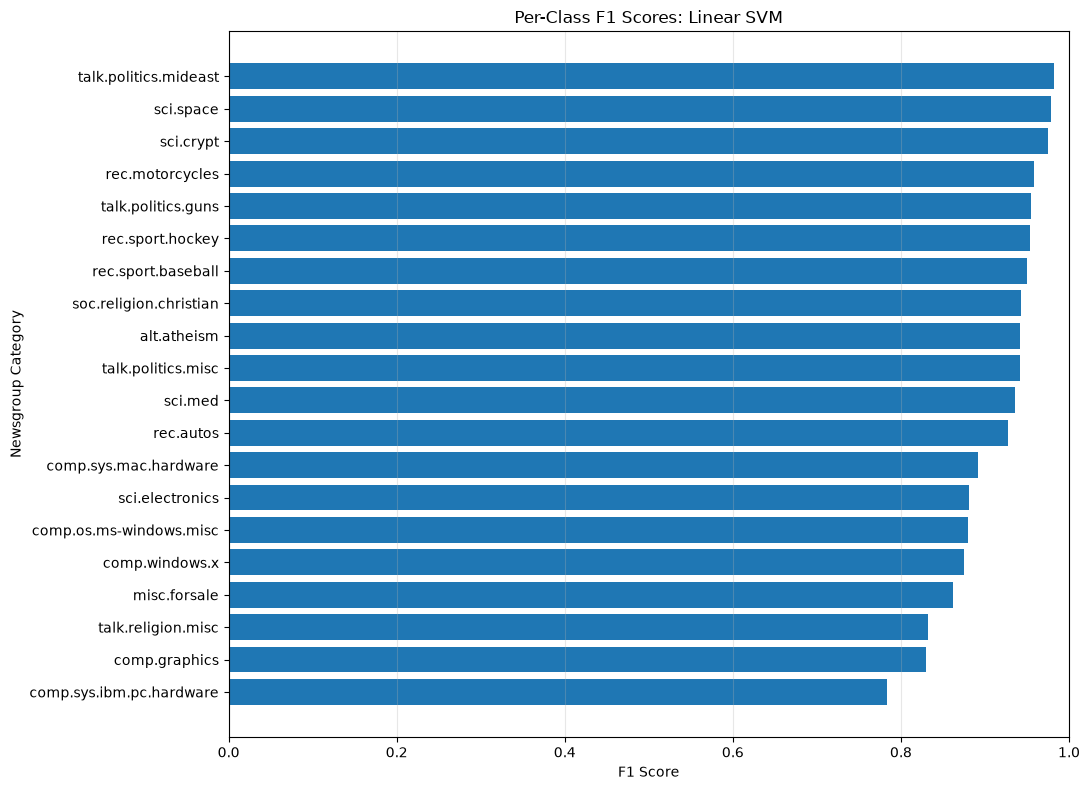

In [26]:
per_class_plot = per_class_df.sort_values("f1_score")

fig, ax = plt.subplots(figsize=(11, 8))

ax.barh(
    per_class_plot["class"],
    per_class_plot["f1_score"],
)

ax.set_title(
    f"Per-Class F1 Scores: {best_run['model']}"
)
ax.set_xlabel("F1 Score")
ax.set_ylabel("Newsgroup Category")
ax.set_xlim(0, 1)

ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

### Interpreting Per-Class Performance

The per-class results show that the strongest overall configuration does not perform equally well across all twenty newsgroup categories.

The highest F1 score is obtained for `talk.politics.mideast` at 0.9826. Other strong results include `sci.space` at 0.9787, `sci.crypt` at 0.9748, and `rec.motorcycles` at 0.9580.

The weakest result is recorded for `comp.sys.ibm.pc.hardware`, with an F1 score of 0.7830. The model also records lower F1 scores for `comp.graphics` at 0.8293 and `talk.religion.misc` at 0.8321.

These differences indicate that some categories are more difficult for the model to distinguish than others. Related subject matter and overlapping vocabulary are possible contributors, particularly among the computer-related categories, but the metric values alone cannot establish the reasons for individual errors.

Class support also matters when interpreting the results. Most categories have between approximately 90 and 120 validation documents, while `talk.religion.misc` has 76. Its performance estimate is consequently based on fewer validation examples than many of the other categories.

The weaker categories provide useful direction for the subsequent error analysis. Examining individual misclassified documents can help determine whether the errors are associated with overlapping subject matter, ambiguous messages, quoted content, or other characteristics of the corpus.

## 1.8 Confusion Matrix Analysis

A confusion matrix provides a more detailed view of the classification errors made by the strongest overall configuration.

The diagonal represents correctly classified documents, while the off-diagonal entries show documents assigned to an incorrect category.

Examining these patterns helps identify which categories are most frequently confused with one another.

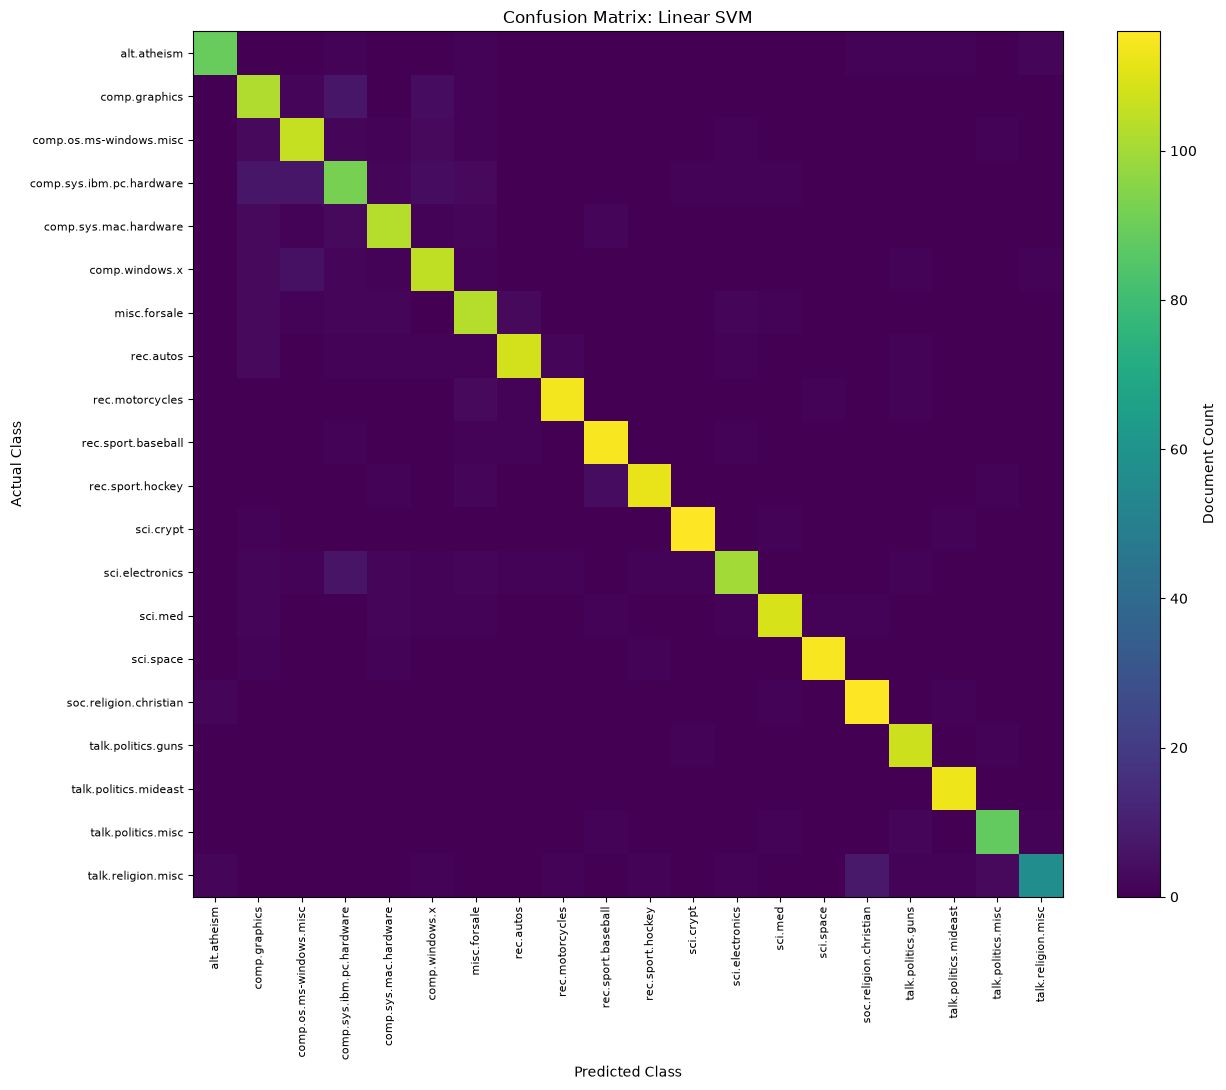

In [12]:
confusion_matrix = np.asarray(
    best_run["confusion_matrix"],
)

class_labels = best_run["class_labels"]

assert confusion_matrix.shape == (
    len(class_labels),
    len(class_labels),
)

fig, ax = plt.subplots(figsize=(13, 11))

image = ax.imshow(
    confusion_matrix,
    interpolation="nearest",
    aspect="auto",
)

ax.set_title(
    f"Confusion Matrix: {best_run['model']}"
)
ax.set_xlabel("Predicted Class")
ax.set_ylabel("Actual Class")

ax.set_xticks(range(len(class_labels)))
ax.set_yticks(range(len(class_labels)))

ax.set_xticklabels(
    class_labels,
    rotation=90,
    fontsize=8,
)

ax.set_yticklabels(
    class_labels,
    fontsize=8,
)

fig.colorbar(image, ax=ax, label="Document Count")

plt.tight_layout()
plt.show()

In [13]:
off_diagonal = confusion_matrix.copy()
np.fill_diagonal(off_diagonal, 0)

error_pairs = (
    pd.DataFrame(
        off_diagonal,
        index=class_labels,
        columns=class_labels,
    )
    .rename_axis("actual_class")
    .reset_index()
    .melt(
        id_vars="actual_class",
        var_name="predicted_class",
        value_name="document_count",
    )
    .query("document_count > 0")
    .sort_values(
        "document_count",
        ascending=False,
    )
    .head(15)
    .reset_index(drop=True)
)

display(error_pairs)

,actual_class,predicted_class,document_count
0,talk.religion.misc,soc.religion.christian,8
1,comp.sys.ibm.pc.hardware,comp.graphics,7
2,comp.graphics,comp.sys.ibm.pc.hardware,7
3,comp.sys.ibm.pc.hardware,comp.os.ms-windows.misc,7
4,sci.electronics,comp.sys.ibm.pc.hardware,6
5,comp.windows.x,comp.os.ms-windows.misc,5
6,comp.sys.ibm.pc.hardware,comp.windows.x,4
7,comp.graphics,comp.windows.x,4
8,rec.sport.hockey,rec.sport.baseball,4
9,comp.os.ms-windows.misc,comp.graphics,3


### Interpreting the Confusion Matrix

The confusion matrix complements the aggregate metrics by showing how the strongest overall configuration distributes its incorrect predictions across the twenty categories.

The most frequent error is the classification of `talk.religion.misc` documents as `soc.religion.christian`, with eight documents assigned to the incorrect category.

Several prominent errors occur among computer-related categories. Seven `comp.sys.ibm.pc.hardware` documents are classified as `comp.graphics`, and seven `comp.graphics` documents are classified as `comp.sys.ibm.pc.hardware`. A further seven `comp.sys.ibm.pc.hardware` documents are classified as `comp.os.ms-windows.misc`.

The results also show confusion between other related categories, including `sci.electronics` and `comp.sys.ibm.pc.hardware`, as well as between `rec.sport.hockey` and `rec.sport.baseball`.

These patterns suggest that some categories may share terminology or subject matter that makes them difficult to distinguish. However, the confusion counts do not establish why a particular document was misclassified. Individual messages may contain overlapping topics, quoted passages, or contextual information that influences the prediction.

The most frequent error pairs provide a reproducible starting point for the dedicated error-analysis notebook. Examining the actual documents and their predictions will allow these patterns to be investigated in greater detail.

## 1.9 Training and Inference Efficiency

Predictive performance is only one aspect of model selection. Computational requirements also matter, particularly given the CPU-only environment used for these experiments.

This section compares the recorded training-related time and end-to-end validation inference time.

The timing measurements require some care when interpreting the results. The classical pipeline includes vectorisation during prediction, whereas the neural-network prediction measurement operates on already encoded sequences. The transformer measurements include their respective tokenisation or embedding-generation stages.

The recorded training-related times also differ in scope. For example, the frozen embedding approach includes training embedding generation in addition to classifier fitting, while the DistilBERT measurement records fine-tuning time.

The following comparisons should therefore be interpreted as measurements of the implemented experimental workflows, not perfectly equivalent measurements of isolated model computation.

In [14]:
efficiency_columns = [
    column
    for column in [
        "model",
        "model_family",
        "representation",
        "macro_f1",
        "training_related_seconds",
        "end_to_end_inference_seconds",
        "end_to_end_latency_ms_per_document",
        "end_to_end_throughput_documents_per_second",
        "training_cost_scope",
        "inference_cost_scope",
    ]
    if column in comparison_df.columns
]

efficiency_df = (
    comparison_df
    .sort_values("macro_f1", ascending=False)
    .reset_index(drop=True)
)

display(efficiency_df[efficiency_columns])

,model,model_family,representation,macro_f1,training_related_seconds,end_to_end_inference_seconds,end_to_end_latency_ms_per_document,end_to_end_throughput_documents_per_second,training_cost_scope,inference_cost_scope
0,Linear SVM,Classical ML,full_message,0.9138,16.2725,1.4973,0.6616,1511.4314,Vectorizer and classifier fitting,Vectorizer transformation and classifier predi...
1,Linear SVM,Classical ML,message_body,0.8947,23.6573,1.5877,0.7016,1425.3327,Vectorizer and classifier fitting,Vectorizer transformation and classifier predi...
2,Logistic Regression,Classical ML,full_message,0.8795,42.9605,1.2576,0.5557,1799.5074,Vectorizer and classifier fitting,Vectorizer transformation and classifier predi...
3,Linear SVM,Classical ML,full_message,0.8789,42.7064,1.4368,0.6349,1575.0673,Vectorizer and classifier fitting,Vectorizer transformation and classifier predi...
4,Logistic Regression,Classical ML,full_message,0.8731,109.5000,1.9411,0.8578,1165.8258,Vectorizer and classifier fitting,Vectorizer transformation and classifier predi...
5,Logistic Regression,Classical ML,message_body,0.8550,60.8556,1.4454,0.6387,1565.6727,Vectorizer and classifier fitting,Vectorizer transformation and classifier predi...
6,Multinomial Naive Bayes,Classical ML,full_message,0.8293,10.6517,1.8191,0.8039,1243.9992,Vectorizer and classifier fitting,Vectorizer transformation and classifier predi...
7,Multinomial Naive Bayes,Classical ML,full_message,0.8272,12.2079,0.9043,0.3996,2502.3546,Vectorizer and classifier fitting,Vectorizer transformation and classifier predi...
8,Logistic Regression,Classical ML,message_body,0.8219,149.1217,1.7969,0.7940,1259.4128,Vectorizer and classifier fitting,Vectorizer transformation and classifier predi...
9,Multinomial Naive Bayes,Classical ML,message_body,0.8053,12.7697,1.6243,0.7178,1393.2300,Vectorizer and classifier fitting,Vectorizer transformation and classifier predi...


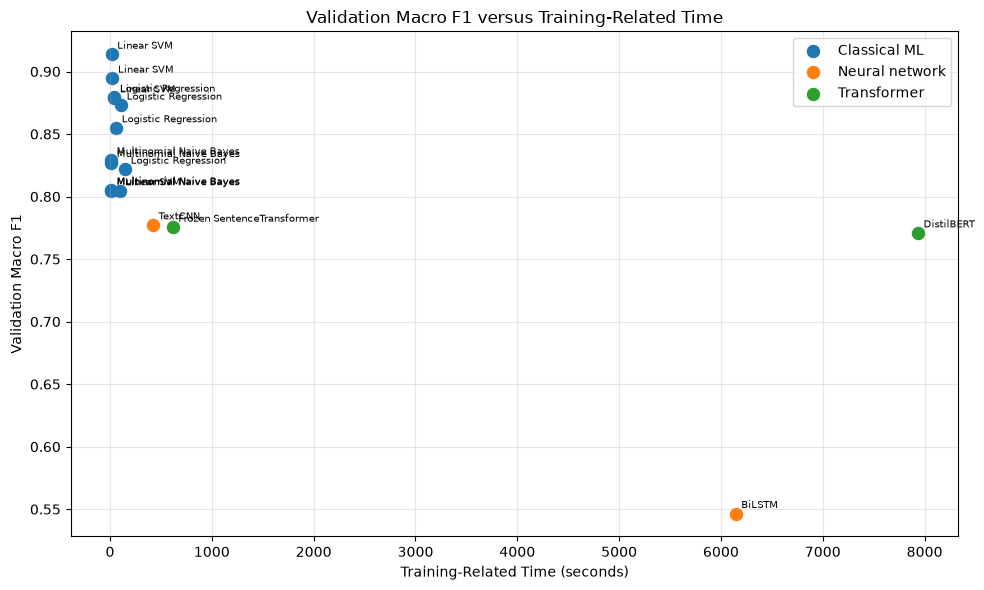

In [15]:
fig, ax = plt.subplots(figsize=(10, 6))

for family, group in efficiency_df.groupby("model_family"):
    ax.scatter(
        group["training_related_seconds"],
        group["macro_f1"],
        label=family,
        s=75,
    )

for _, row in efficiency_df.iterrows():
    ax.annotate(
        row["model"],
        (
            row["training_related_seconds"],
            row["macro_f1"],
        ),
        fontsize=7,
        xytext=(4, 4),
        textcoords="offset points",
    )

ax.set_title("Validation Macro F1 versus Training-Related Time")
ax.set_xlabel("Training-Related Time (seconds)")
ax.set_ylabel("Validation Macro F1")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Interpreting Training Efficiency

The training-time measurements show substantial differences in the computational cost of the implemented approaches.

TextCNN required approximately 423 seconds, or seven minutes, to train. The BiLSTM required approximately 6,145 seconds, or 102 minutes. In this experiment, BiLSTM training therefore took roughly fourteen and a half times as long as TextCNN training, while achieving a lower validation macro F1: 0.5465 compared with 0.7774.

DistilBERT fine-tuning required approximately two hours and twelve minutes. Its validation macro F1 of 0.7709 was lower than the strongest classical configuration and slightly lower than TextCNN.

The classical experiments generally required considerably less training time under the recorded conditions. The strongest Linear SVM configuration achieved a macro F1 of 0.9138 with a recorded training-related time of approximately 16 seconds.

These results demonstrate that the additional computational cost of the neural-network and transformer experiments did not produce a corresponding improvement in validation macro F1 in the current experiments.

The timing values should nevertheless be treated as measurements of the implemented workflows rather than perfectly standardised benchmarks. The recorded training-related time includes different operations for different model families. For example, the frozen embedding experiment includes embedding generation as well as classifier fitting, whereas the DistilBERT measurement records fine-tuning time.

The measurements are therefore useful for assessing the practical cost of the experiments conducted, but they should not be interpreted as a definitive comparison of the computational efficiency of the model architectures in isolation.

In [16]:
inference_columns = [
    column
    for column in [
        "model",
        "model_family",
        "macro_f1",
        "end_to_end_inference_seconds",
        "end_to_end_latency_ms_per_document",
        "end_to_end_throughput_documents_per_second",
        "inference_cost_scope",
    ]
    if column in comparison_df.columns
]

display(
    comparison_df[
        inference_columns
    ].sort_values(
        "end_to_end_inference_seconds",
        ascending=True,
    )
)

,model,model_family,macro_f1,end_to_end_inference_seconds,end_to_end_latency_ms_per_document,end_to_end_throughput_documents_per_second,inference_cost_scope
7,Multinomial Naive Bayes,Classical ML,0.8272,0.9043,0.3996,2502.3546,Vectorizer transformation and classifier predi...
12,TextCNN,Neural network,0.7774,0.9310,0.4114,2430.6530,Model prediction on encoded sequences
10,Multinomial Naive Bayes,Classical ML,0.8046,1.1184,0.4942,2023.4066,Vectorizer transformation and classifier predi...
2,Logistic Regression,Classical ML,0.8795,1.2576,0.5557,1799.5074,Vectorizer transformation and classifier predi...
11,Linear SVM,Classical ML,0.8046,1.3559,0.5992,1668.9991,Vectorizer transformation and classifier predi...
3,Linear SVM,Classical ML,0.8789,1.4368,0.6349,1575.0673,Vectorizer transformation and classifier predi...
5,Logistic Regression,Classical ML,0.8550,1.4454,0.6387,1565.6727,Vectorizer transformation and classifier predi...
0,Linear SVM,Classical ML,0.9138,1.4973,0.6616,1511.4314,Vectorizer transformation and classifier predi...
1,Linear SVM,Classical ML,0.8947,1.5877,0.7016,1425.3327,Vectorizer transformation and classifier predi...
9,Multinomial Naive Bayes,Classical ML,0.8053,1.6243,0.7178,1393.2300,Vectorizer transformation and classifier predi...


### Interpreting Inference Efficiency

Inference time and throughput provide further information about the practical requirements of using the trained models.

End-to-end inference time measures the time required to process the validation documents within the recorded inference workflow. Throughput expresses the number of documents processed per second, while latency represents the average time per document.

The results show that inference performance varies across configurations. For example, the Multinomial Naive Bayes configuration using count features and complete messages records an end-to-end inference time of approximately 0.90 seconds. TextCNN records approximately 0.93 seconds under its measured inference procedure.

These measurements should be interpreted alongside their computational scope. Classical pipelines include the relevant vectorisation and prediction operations. The neural-network experiments operate on prepared input sequences, while transformer-based approaches include their respective tokenisation or embedding-generation stages.

Consequently, the values describe the end-to-end inference workflows implemented in this project. They are not perfectly controlled measurements of the prediction operations alone.

The measurements are still useful when considering the practical cost of processing documents using the saved experimental configurations. A deployment-focused benchmark would require a common measurement procedure, consistent hardware conditions, and clearly defined treatment of preprocessing, model loading, and batch processing.

## 1.10 Model Artifact Size and Memory Usage

The size of a saved model artifact is relevant when considering storage requirements and deployment.

However, the artifact-size measurements do not cover identical components for every model. Classical artifacts contain the fitted vectorisation and classification pipeline. Neural-network artifacts contain their saved model parameters and vocabulary. The DistilBERT artifact measurement includes the fine-tuned model and tokenizer, whereas the frozen embedding experiment records the classifier artifact without including the pretrained SentenceTransformer encoder.

Memory measurements also have different monitoring scopes. They should not be treated as directly equivalent estimates of peak memory consumption across all model families.

The following analysis presents the available measurements together with their recorded scope.

In [17]:
artifact_columns = [
    column
    for column in [
        "model",
        "model_family",
        "artifact_size_bytes",
        "artifact_size_scope",
    ]
    if column in comparison_df.columns
]

artifact_df = comparison_df[artifact_columns].copy()

if "artifact_size_bytes" in artifact_df.columns:
    artifact_df["artifact_size_mb"] = (
        artifact_df["artifact_size_bytes"] / (1024 ** 2)
    )

    artifact_df = artifact_df.sort_values(
        "artifact_size_mb",
        ascending=False,
    )

display(artifact_df)

,model,model_family,artifact_size_bytes,artifact_size_scope,artifact_size_mb
14,DistilBERT,Transformer,268606876,Fine-tuned model and tokenizer,256.1635
6,Multinomial Naive Bayes,Classical ML,35902689,Fitted scikit-learn pipeline,34.2395
9,Multinomial Naive Bayes,Classical ML,35900497,Fitted scikit-learn pipeline,34.2374
7,Multinomial Naive Bayes,Classical ML,35102605,Fitted scikit-learn pipeline,33.4765
10,Multinomial Naive Bayes,Classical ML,35100413,Fitted scikit-learn pipeline,33.4744
2,Logistic Regression,Classical ML,19902636,Fitted scikit-learn pipeline,18.9806
0,Linear SVM,Classical ML,19902488,Fitted scikit-learn pipeline,18.9805
5,Logistic Regression,Classical ML,19900444,Fitted scikit-learn pipeline,18.9785
1,Linear SVM,Classical ML,19900296,Fitted scikit-learn pipeline,18.9784
4,Logistic Regression,Classical ML,19102536,Fitted scikit-learn pipeline,18.2176


In [18]:
memory_columns = [
    column
    for column in comparison_df.columns
    if "memory" in column.lower()
    or "rss" in column.lower()
]

if memory_columns:
    display(
        comparison_df[
            [
                column
                for column in [
                    "model",
                    "model_family",
                    *memory_columns,
                ]
                if column in comparison_df.columns
            ]
        ]
    )
else:
    print(
        "No memory measurements are available in the consolidated "
        "comparison records."
    )

,model,model_family,peak_sampled_rss_bytes
0,Linear SVM,Classical ML,NaN
1,Linear SVM,Classical ML,NaN
2,Logistic Regression,Classical ML,NaN
3,Linear SVM,Classical ML,NaN
4,Logistic Regression,Classical ML,NaN
5,Logistic Regression,Classical ML,NaN
6,Multinomial Naive Bayes,Classical ML,NaN
7,Multinomial Naive Bayes,Classical ML,NaN
8,Logistic Regression,Classical ML,NaN
9,Multinomial Naive Bayes,Classical ML,NaN


### Interpreting Artifact Size and Memory Measurements

The artifact-size results show that the storage requirements differ considerably across the evaluated approaches.

The DistilBERT model and tokenizer occupy approximately 256 MB in the recorded artifact. The fitted Multinomial Naive Bayes pipelines occupy approximately 34 MB, while the Logistic Regression and Linear SVM pipelines are generally around 18–19 MB.

These values represent the saved components recorded for each experiment, rather than identical deployment packages. In particular, the frozen SentenceTransformer experiment records the classifier artifact but excludes the pretrained sentence encoder required to generate embeddings during inference. Its recorded classifier size therefore does not represent the complete storage requirement of that approach.

The memory results require similar caution. Sampled peak RSS measurements are available for the two transformer experiments: approximately 2.39 GB for DistilBERT and 1.74 GB for the frozen embedding approach. The comparison records do not contain corresponding memory measurements for the classical and neural-network experiments.

These values should not be treated as directly comparable peak-memory benchmarks across all model families. Monitoring scope and timing differ between experiments, and memory measurements are unavailable for several configurations. A more complete deployment assessment would require a standardised procedure that includes all components needed to load and serve each model.

In [19]:
best_overall = max(
    runs,
    key=lambda run: run["macro_f1"],
)

best_classical_body = (
    message_body_df[
        message_body_df["model_family"] == "Classical ML"
    ]
    .sort_values("macro_f1", ascending=False)
    .iloc[0]
)

best_neural = (
    comparison_df[
        comparison_df["model_family"] == "Neural network"
    ]
    .sort_values("macro_f1", ascending=False)
    .iloc[0]
)

best_transformer = (
    comparison_df[
        comparison_df["model_family"] == "Transformer"
    ]
    .sort_values("macro_f1", ascending=False)
    .iloc[0]
)

selection_summary = pd.DataFrame(
    [
        {
            "comparison": "Best overall configuration",
            "model": best_overall["model"],
            "representation": best_overall["representation"],
            "macro_f1": best_overall["macro_f1"],
        },
        {
            "comparison": "Best classical message-body configuration",
            "model": best_classical_body["model"],
            "representation": best_classical_body["representation"],
            "macro_f1": best_classical_body["macro_f1"],
        },
        {
            "comparison": "Best neural-network configuration",
            "model": best_neural["model"],
            "representation": best_neural["representation"],
            "macro_f1": best_neural["macro_f1"],
        },
        {
            "comparison": "Best transformer configuration",
            "model": best_transformer["model"],
            "representation": best_transformer["representation"],
            "macro_f1": best_transformer["macro_f1"],
        },
    ]
)

display(selection_summary)

,comparison,model,representation,macro_f1
0,Best overall configuration,Linear SVM,full_message,0.9138
1,Best classical message-body configuration,Linear SVM,message_body,0.8947
2,Best neural-network configuration,TextCNN,message_body,0.7774
3,Best transformer configuration,Frozen SentenceTransformer,message_body,0.7755


## 1.11 Overall Findings and Model Selection

The combined results provide a basis for assessing predictive performance alongside the computational requirements of the evaluated approaches.

The strongest overall validation configuration is the Linear SVM using TF-IDF features and complete messages. It achieves a macro F1 of 0.9138 and an accuracy of 0.9147.

The strongest classical configuration using message bodies is also a Linear SVM with TF-IDF features, achieving a macro F1 of 0.8947. This result is particularly relevant because it retains a substantial advantage over the evaluated neural-network and transformer configurations when the broad input representation is held constant.

TextCNN is the strongest neural-network configuration, achieving a macro F1 of 0.7774. It also requires substantially less training time than the BiLSTM, which achieves 0.5465 macro F1. The frozen SentenceTransformer approach and DistilBERT achieve similar validation results, with macro F1 scores of 0.7755 and 0.7709 respectively.

The results therefore favour the Linear SVM as the leading candidate for further evaluation. It combines the strongest validation performance with comparatively low recorded training time. TextCNN remains a useful neural-network result, while the transformer experiments provide evidence about the performance and resource requirements of more computationally demanding approaches.

This selection is provisional. The strongest validation configuration should not automatically be treated as the final deployed model. Its performance must still be assessed using the official test set, and the remaining evaluation requirements must be considered before a final model is selected.

### Research Question Implications

The comparison contributes to the project's research questions in several ways.

**Classical versus deep-learning approaches:** The strongest classical configuration achieves higher validation macro F1 than the evaluated neural-network and transformer configurations. The message-body comparison indicates that this advantage is not explained entirely by the use of complete messages.

**Feature extraction and text representation:** The classical experiments show that performance depends on the combination of classifier, feature extraction method, and text representation. Complete-message configurations generally outperform their corresponding message-body configurations in the experiments conducted. This supports further investigation into the contribution of headers, quoted passages, and other message content.

**Neural-network performance:** TextCNN outperforms the BiLSTM in both validation macro F1 and recorded training time. The results therefore do not support the assumption that the more computationally expensive recurrent architecture necessarily provides better performance for this dataset.

**Transformer performance:** Neither DistilBERT nor the frozen sentence embedding approach surpasses the strongest classical configuration on the current validation split. Their computational and storage requirements must therefore be considered alongside their observed predictive performance.

**Efficiency:** Training time, inference time, throughput, artifact size, and available memory measurements provide additional information for assessing practical trade-offs. However, differences in measurement scope and missing measurements limit the extent to which these values can be treated as directly comparable benchmarks.

The findings remain specific to the 20 Newsgroups dataset, the selected development split, and the experimental configurations evaluated. They should not be generalised beyond this setting without further evidence.

## 1.12 Limitations of the Comparison

Several limitations should be considered when interpreting the results.

1. **Single development split:** The experiments use one fixed training and validation partition. Performance differences may therefore partly reflect the characteristics of that particular split.

2. **No repeated-seed evaluation:** The comparison does not establish whether the observed differences are stable across different random initialisations. This is particularly relevant when interpreting relatively small differences between configurations.

3. **Different text representations:** The overall ranking combines complete-message and message-body experiments. The separate message-body comparison reduces this issue but does not eliminate all differences between experimental procedures.

4. **Different training and inference procedures:** Classical models, neural networks, and transformers require different preprocessing and input preparation. The recorded timing measurements describe the implemented workflows and do not represent identical computational scopes.

5. **Artifact and memory measurement limitations:** Some artifact measurements exclude pretrained components required for inference. Memory measurements are available for only two experiments, and the monitoring procedures do not provide a fully standardised comparison across all model families.

6. **Validation-based selection:** The results are used to identify promising configurations during model development. Final performance must still be established using the official test set, which has not been used in this notebook.

7. **No statistical significance testing:** The observed differences are descriptive. Repeated experiments or suitable statistical tests would be required to determine whether particular performance differences are statistically significant.

These limitations do not invalidate the comparison. They define the scope of the conclusions that can reasonably be drawn from the available experimental evidence.

## 1.13 Conclusion

The model comparison identifies the Linear SVM with TF-IDF features and complete-message representation as the strongest configuration among the sixteen evaluated experiments. It achieves a validation macro F1 of 0.9138.

The controlled message-body comparison also favours classical machine learning. Its strongest configuration achieves a macro F1 of 0.8947, exceeding the results obtained by the evaluated neural-network and transformer approaches.

Among the neural-network models, TextCNN achieves stronger validation performance than the BiLSTM while requiring substantially less training time. The transformer approaches achieve results similar to TextCNN but do not surpass the strongest classical configuration in the current experiments.

Taken together, the results support carrying the Linear SVM forward as the leading candidate for further evaluation. This decision reflects its validation performance and comparatively modest computational requirements, rather than an assumption that classical models are universally superior.

The findings remain provisional because the official test set has not yet been evaluated. The next notebook will investigate classification errors in greater detail by examining misclassified documents and the patterns underlying the model's predictions.